## Module 3: Computational Drug Discovery Project

Team members: Jenny Mejia & Jenna Nguyen

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background:
Obesity is a chronic, progressive, and multifactorial disease characterized by excessive body fat accumulation, typically diagnosed in adults with a body mass index (BMI) ≥30 kg/m². Its prevalence in the United States has increased significantly over recent decades, making it a major public health concern [1]. Obesity increases the risk of type 2 diabetes, cardiovascular disease, and other metabolic complications. Current treatments include lifestyle modifications, bariatric surgery, and pharmacological therapies such as glucagon-like peptide-1 (GLP-1) receptor agonists. Semaglutide (Ozempic and Wegovy) promotes weight loss by activating GLP-1 receptors, reducing appetite, and increasing satiety. However, treatment effectiveness varies among individuals due to differences in pharmacokinetics, receptor signaling, and metabolic characteristics [2]. Additionally, weight regain following treatment discontinuation remains a significant challenge, often requiring continued pharmacological intervention to maintain weight loss [3]. Emerging oral GLP-1 receptor agonists, such as orforglipron, have demonstrated promising weight reduction in clinical trials. These limitations highlight the need for improved treatments that provide sustained weight reduction, convenient administration, and optimized drug efficacy. Developing novel oral GLP-1 receptor agonists, such as Cavalitide, may help address these challenges.




## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

Below, we define the receptor model, where GLP1 (L1) and the drug (L2) both bind and activate GLP1R. GLP1 is fixed at its fasting level (0.015 nM, Kd1 = 0.17 nM), so the drug's Kd2 is the only value we fit. We load both the Cavalitide and semaglutide data. We fit Kd2 for both drugs using brute force (testing 100 values) and curve_fit, and pick the value with the lowest sum of squared errors (SSE).

Cavalitide data: 12 concentrations from 0.001 to 100 nM
Semaglutide data: 12 concentrations from 0.001 to 100 nM
Drug          Brute-force Kd2          curve_fit Kd2      SSE
Cavalitide           0.074 nM        0.077 ± 0.005 nM   0.0052
Semaglutide          0.335 nM        0.350 ± 0.019 nM   0.0044

Cavalitide binds GLP1R 4.5x more tightly than semaglutide and 2.2x more tightly than native GLP1.


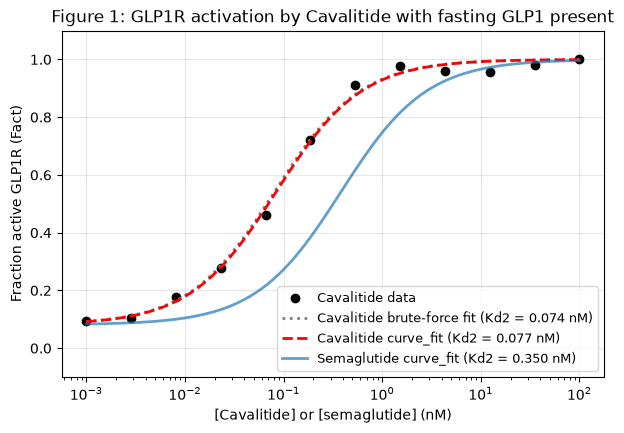

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Fixed Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # default 0.38 L2, semaglutide (to fit)
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

# Load the data
cav = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
sema = np.loadtxt("semaglutide_data.csv", delimiter=",", skiprows=1)
L2_cav, Fact_cav = cav[:, 0], cav[:, 1]
L2_sema, Fact_sema = sema[:, 0], sema[:, 1]

print(f"Cavalitide data: {len(L2_cav)} concentrations from {L2_cav.min():g} to {L2_cav.max():g} nM")
print(f"Semaglutide data: {len(L2_sema)} concentrations from {L2_sema.min():g} to {L2_sema.max():g} nM")

def fit_Kd2(L2_data, Fact_data):
    """Finds the drug Kd (Kd2) that best fits the data, using two methods."""
    # Approach 1: brute force -- tries 100 candidate Kd2 values and keeps the one with the lowest sum of squared errors (SSE) between the data and the model.
    Kd2_candidates = np.logspace(-3, 2, 100)   # [nM]
    SSE_brute = np.inf
    for Kd2_try in Kd2_candidates:
        SSE = np.sum((Fact_data - Fact(L1, L2_data, Kd1, Kd2_try))**2)
        if SSE < SSE_brute:
            SSE_brute = SSE
            Kd2_brute = Kd2_try

    # Approach 2: scipy's curve_fit (nonlinear least squares) -- searches continuously for the minimum SSE.
    # Only Kd2 is fitted; L1 and Kd1 are held fixed. bounds keep Kd2 positive.
    popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                           L2_data, Fact_data, p0=[0.1], bounds=(0, np.inf))
    Kd2_fit = popt[0]
    Kd2_err = np.sqrt(pcov[0, 0])              # standard error of the fitted Kd2
    SSE_fit = np.sum((Fact_data - Fact(L1, L2_data, Kd1, Kd2_fit))**2)
    return Kd2_brute, SSE_brute, Kd2_fit, Kd2_err, SSE_fit

# Fits Cavalitide, and semaglutide with the same method so the two Kd values are directly comparable.
fits = {"Cavalitide": fit_Kd2(L2_cav, Fact_cav),
        "Semaglutide": fit_Kd2(L2_sema, Fact_sema)}

print(f"{'Drug':12s} {'Brute-force Kd2':>16s} {'curve_fit Kd2':>22s} {'SSE':>8s}")
for drug, (Kb, SSEb, Kf, Kerr, SSEf) in fits.items():
    print(f"{drug:12s} {Kb:13.3f} nM {Kf:12.3f} ± {Kerr:.3f} nM {SSEf:8.4f}")

Kd2_cav = fits["Cavalitide"][2]
Kd2_sema = fits["Semaglutide"][2]
print(f"\nCavalitide binds GLP1R {Kd2_sema/Kd2_cav:.1f}x more tightly than semaglutide "
      f"and {Kd1/Kd2_cav:.1f}x more tightly than native GLP1.")

# Creates Figure 1: Cavalitide binding data with both fitted curves, plus the semaglutide fit for comparison.
Kd2_brute_cav = fits["Cavalitide"][0]

plt.figure(figsize=(7, 4.5))
plt.semilogx(L2_cav, Fact_cav, "ko", label="Cavalitide data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute_cav), ":", color="gray", lw=2,
             label=f"Cavalitide brute-force fit (Kd2 = {Kd2_brute_cav:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_cav), "r--", lw=2,
             label=f"Cavalitide curve_fit (Kd2 = {Kd2_cav:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_sema), color="tab:blue", lw=2, alpha=0.7,
             label=f"Semaglutide curve_fit (Kd2 = {Kd2_sema:.3f} nM)")
plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] or [semaglutide] (nM)")
plt.ylabel("Fraction active GLP1R (Fact)")
plt.title("Figure 1: GLP1R activation by Cavalitide with fasting GLP1 present")
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.show()

Figure 1 shows that the fitted curve closely follows the Cavalitide experimental data, suggesting a good fit. The semaglutide curve is shifted to the right because it requires a higher concentration to activate the same fraction of receptors. The fitted Kd of Cavalitide is 0.077 nM, compared with 0.350 nM for semaglutide. A lower Kd indicates tighter binding, so Cavalitide has approximately 4.5 times greater binding affinity for GLP1R in our model. 

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

Below, we set up the PK model. Each dose enters a depot (gut or injection site), is absorbed into the blood at rate ka, and is eliminated at rate ke. The equations are solved with solve_ivp instead of the original Euler loop. 

Ozempic                  free Cc over last interval: mean 0.608 nM (min 0.491, max 0.679)
Wegovy                   free Cc over last interval: mean 0.599 nM (min 0.599, max 0.599)
Cavalitide               free Cc over last interval: mean 0.601 nM (min 0.600, max 0.601)
Cavalitide (optimized)   free Cc over last interval: mean 0.505 nM (min 0.504, max 0.505)


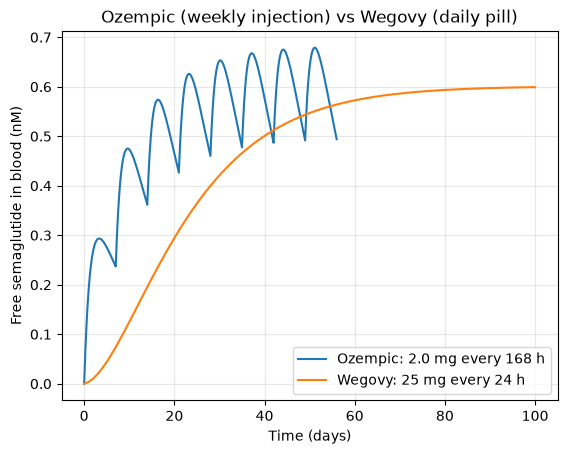

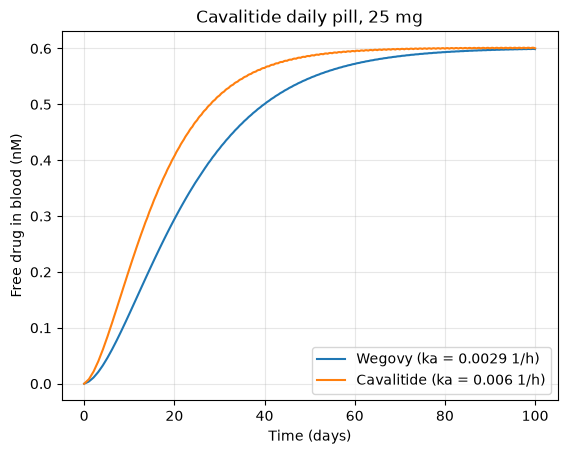

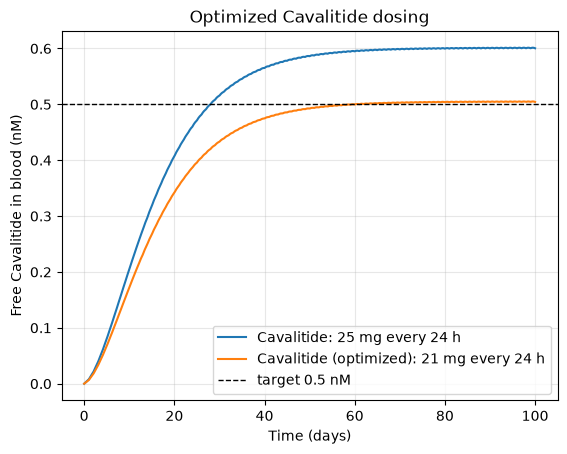

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
drug = 'Ozempic'
#drug = 'Wegovy'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    'Cavalitide': dict(Favailable=0.01, # cavalitide oral bioavailability
                       ka=0.006,          # 1/h, increased absorption rate
                       D=25,              # mg
                       interval=24,       # h (daily)
                       n_doses=100,
                       depot='gut (oral)'),
    'Cavalitide (optimized)': dict(Favailable=0.01, # optimized Cavalitide dosing (lower daily dose)
                       ka=0.006,
                       D=21,              # mg  <-- changed from 25 mg
                       interval=24,       # h (daily)
                       n_doses=100,
                       depot='gut (oral)'),
}

p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, output time spacing (solve_ivp picks its own internal steps)

def ODEfunc(t, y, ka):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(Favailable, ka, D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)

        # solve_ivp replaces the explicit Euler loop
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        args=(ka,), method='RK45', rtol=1e-8, atol=1e-10)
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM


results = {}

for drug_name, p in products.items():
    t, Asc, Cc = simulate(
        p['Favailable'],
        p['ka'],
        p['D'],
        p['n_doses'],
        p['interval'],
        dt
    )

    results[drug_name] = (t, Asc, Cc)

    last = t >= t[-1] - p['interval']

    print(f"{drug_name:24s} free Cc over last interval: mean {np.mean(Ffree*Cc[last]):.3f} nM "
          f"(min {np.min(Ffree*Cc[last]):.3f}, max {np.max(Ffree*Cc[last]):.3f})")
 
# --- Figure 1: Ozempic vs Wegovy ---
plt.figure()
for drug in ['Ozempic', 'Wegovy']:
    t, Asc, Cc = results[drug]
    plt.plot(t / 24, Ffree*Cc, label=f"{drug}: {products[drug]['D']} mg every {products[drug]['interval']} h")
plt.xlabel("Time (days)")
plt.ylabel("Free semaglutide in blood (nM)")
plt.title("Ozempic (weekly injection) vs Wegovy (daily pill)")
plt.legend()
plt.grid(alpha=0.3)
 
# --- Figure 2: Cavalitide vs Wegovy ---
plt.figure()
for drug in ['Wegovy', 'Cavalitide']:
    t, Asc, Cc = results[drug]
    plt.plot(t / 24, Ffree*Cc, label=f"{drug} (ka = {products[drug]['ka']} 1/h)")
plt.xlabel("Time (days)")
plt.ylabel("Free drug in blood (nM)")
plt.title("Cavalitide daily pill, 25 mg")
plt.legend()
plt.grid(alpha=0.3)
 
# --- Figure 3: optimized Cavalitide dosing ---
plt.figure()
for drug in ['Cavalitide', 'Cavalitide (optimized)']:
    t, Asc, Cc = results[drug]
    plt.plot(t / 24, Ffree*Cc, label=f"{drug}: {products[drug]['D']} mg every {products[drug]['interval']} h")
plt.axhline(0.5, color='k', ls='--', lw=1, label="target 0.5 nM")
plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide in blood (nM)")
plt.title("Optimized Cavalitide dosing")
plt.legend()
plt.grid(alpha=0.3)
 
plt.show()






Figure 2) Ozempic's weekly injection produces fluctuations in blood concentration between approximately 0.49 and 0.68 nM, while the simulated daily oral semaglutide formulation rises more gradually and approaches approximately 0.60 nM. These findings are consistent with a systematic review of semaglutide pharmacokinetics [7], which reported that semaglutide has a long half-life that supports once-weekly subcutaneous administration and that drug exposure increases with dose. The differences between the simulated profiles demonstrate how dosing frequency and absorption rates influence blood concentration over time. However, our model assumes constant absorption and elimination rates, while published research shows that food intake, water consumption, and dosing conditions can affect oral semaglutide exposure [7].

Figure 3) Cavalitide's increased absorption rate (ka = 0.006 h⁻¹) allows it to reach 90% of its steady-state concentration sooner than the simulated oral semaglutide formulation (34 versus 48 days). However, both treatments approach approximately 0.60 nM because they share the same dose, bioavailability, and elimination parameters. This agrees with the behavior expected from our first-order pharmacokinetic model, in which increasing the absorption rate changes the concentration-time profile without changing the average steady-state concentration. Previous research on GLP-1 receptor agonists [6] demonstrated that pharmacokinetics can involve more complex processes, including receptor-mediated internalization, tissue distribution, and nonlinear elimination. Therefore, our simplified model may not fully predict Cavalitide's actual absorption or clearance in patients.

Figure 4) The daily Cavalitide dose was reduced from 25 mg to 21 mg while maintaining 
once-daily administration. Since steady-state average concentration is proportional to dose in our linear model, the estimated dose was calculated as 25 × (0.5/0.6) ≈ 21 mg. This adjustment produced a predicted concentration of approximately 0.505 nM, closely matching the target of 0.5 nM. The lower dose represents a 16% reduction in drug administered while maintaining the desired concentration. Published pharmacokinetic research [7] also reported dose-dependent semaglutide exposure, supporting the general relationship between dose and drug concentration. Maintaining daily oral administration may improve convenience for patients who prefer to avoid injections. However, a lower dose does not automatically guarantee fewer side effects or lower costs, and the optimal dosing strategy would require clinical testing. Overall, these simulations suggest that Cavalitide's dosing could be optimized to achieve the target blood concentration with less drug, although further experimental validation is necessary.


## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


Below is a combination of models: the PK model gives the free Cavalitide concentration over time, and the receptor model (using Kd = 0.077 nM) converts it into the fraction of active receptors. We also calculate the dose needed for 90% activation.

Cavalitide 21 mg     day 100: free Cavalitide = 0.504 nM, Fact = 0.869
Cavalitide 28.5 mg   day 100: free Cavalitide = 0.684 nM, Fact = 0.900
Baseline (GLP1 only, no drug): Fact = 0.081


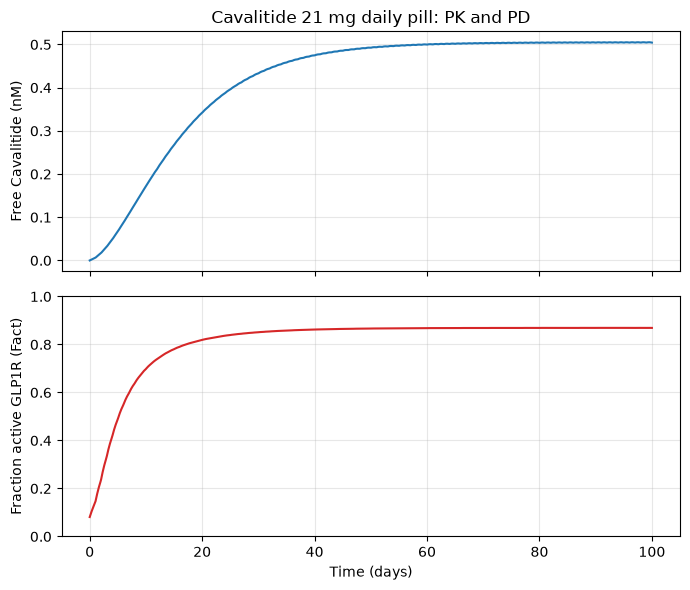

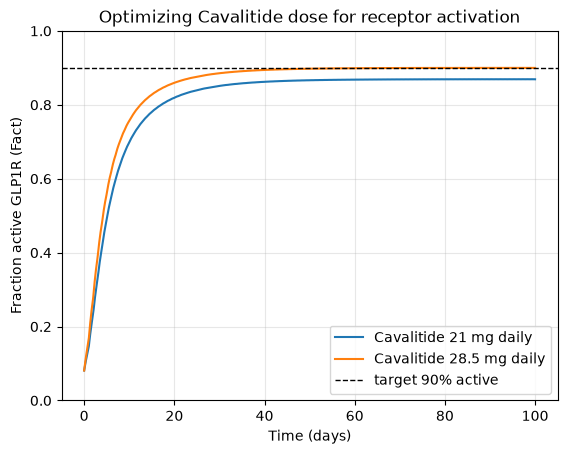

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== PD (ligand-receptor) parameters from Task 1 =====
Kd1 = 0.17      # nM, GLP1
Kd2 = 0.077     # nM, Cavalitide (fitted in Task 1)
L1 = 0.015      # nM, GLP1 (fasting)

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# ===== choose product: 'Ozempic' or 'Wegovy' =====
drug = 'Ozempic'
#drug = 'Wegovy'

# product-specific parameters
products = {
    'Cavalitide 21 mg': dict(Favailable=0.01,  # oral bioavailability
                             ka=0.006,         # 1/h, absorption rate
                             D=21,             # mg per dose
                             interval=24,      # h (daily)
                             n_doses=100),     # 100 days
    'Cavalitide 28.5 mg': dict(Favailable=0.01,
                               ka=0.006,
                               D=28.5,         # mg  <-- changed from 21 mg
                               interval=24,
                               n_doses=100),
}

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, output time spacing (solve_ivp picks its own internal steps)

def ODEfunc(t, y, ka):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(Favailable, ka, D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)

        # solve_ivp replaces the explicit Euler loop
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg,
                        args=(ka,), method='RK45', rtol=1e-8, atol=1e-10)
        y_seg = sol.y

        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
results = {}
for name, p in products.items():
    t, Asc, Cc = simulate(p['Favailable'], p['ka'], p['D'], p['n_doses'], p['interval'], dt)
    L2_free = Ffree * Cc                      # free Cavalitide (nM) binds the receptor
    F = Fact(L1, L2_free, Kd1, Kd2)           # PD: fraction of active GLP1R
    results[name] = (t, L2_free, F)
    print(f"{name:20s} day 100: free Cavalitide = {L2_free[-1]:.3f} nM, Fact = {F[-1]:.3f}")

print(f"Baseline (GLP1 only, no drug): Fact = {Fact(L1, 0, Kd1, Kd2):.3f}")

# ===== Figure 1 (Task 3.1): PK and PD over 100 days at 21 mg =====
t, L2_free, F = results['Cavalitide 21 mg']
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 6))
ax1.plot(t / 24, L2_free)
ax1.set_ylabel("Free Cavalitide (nM)")
ax1.set_title("Cavalitide 21 mg daily pill: PK and PD")
ax1.grid(alpha=0.3)
ax2.plot(t / 24, F, color='tab:red')
ax2.set_xlabel("Time (days)")
ax2.set_ylabel("Fraction active GLP1R (Fact)")
ax2.set_ylim(0, 1)
ax2.grid(alpha=0.3)
plt.tight_layout()

# ===== Figure 2 (Task 3.2): optimized dose for ~90% active receptors =====
plt.figure()
for name in products:
    t, L2_free, F = results[name]
    plt.plot(t / 24, F, label=f"{name} daily")
plt.axhline(0.9, color='k', ls='--', lw=1, label="target 90% active")
plt.xlabel("Time (days)")
plt.ylabel("Fraction active GLP1R (Fact)")
plt.title("Optimizing Cavalitide dose for receptor activation")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

Figure 3.1) Over the first 100 days at 21 mg, receptor activation rises from 8% (GLP1 alone) to about 85% by day 30 and levels off at about 87%, even though the drug concentration is still rising, because Cavalitide’s tight binding fills most receptors early.

Figure 3.2) We increased the daily dose from 21 mg to 28.5 mg, which reaches 90% active receptors at steady state. More active receptors means stronger appetite suppression and blood sugar control, which should lead to more weight loss, and the higher dose also reaches high activation sooner. However, it takes about 36% more drug to go from 87% to 90%, which could increase side effects and cost for a small gain.


Figure 3.2) We increased the daily dose from 21 mg to 28.5 mg, which reaches 90% active receptors at steady state. More active receptors means stronger appetite suppression and blood sugar control, which should lead to more weight loss, and the higher dose also reaches high activation sooner. However, it takes about 36% more drug to go from 87% to 90%, which could increase side effects and cost for a small gain.

## Verify and Validate:

**Task 1: Receptor binding model.** To verify our receptor binding model in Task 1, we applied the same model and code to the semaglutide binding data, which has a published receptor affinity we could compare against. This comparison is supported by published research reporting a semaglutide receptor affinity of 0.38 ± 0.06 nM, which differs from our modeled value by only 7.9% [4]. Previous studies have also demonstrated concentration-dependent GLP-1 responses and the importance of receptor binding in pharmacodynamic modeling [5,6]. An advantage of Cavalitide's higher affinity is that a lower blood concentration may be needed to achieve the same receptor activation, potentially allowing for smaller doses. However, Yang and Yang [7] demonstrated that semaglutide exposure also depends on pharmacokinetic factors, including absorption and dosing conditions, meaning stronger binding does not necessarily guarantee a smaller oral dose. A disadvantage is that receptor activation approaches saturation at higher concentrations, so increasing the dose may provide limited additional benefits. Clinical research has also identified gastrointestinal side effects associated with oral and injectable semaglutide [8], emphasizing the importance of evaluating drug safety. A limitation of the task one model is that it assumes simplified receptor binding and does not account for receptor internalization, drug absorption, or patient variability [6,7]. Therefore, although Cavalitide demonstrates promising binding affinity, further experimental validation is necessary to determine its effectiveness and safety compared with semaglutide.

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

Our analyses suggest that Cavalitide could be a strong competitor to both oral and injected semaglutide. Fitting the binding data showed that Cavalitide has a Kd of 0.077 nM, about 4.5 times lower than semaglutide's 0.35 nM, so it activates the GLP1 receptor at much lower concentrations. In the PK model, Cavalitide's faster absorption did not raise its steady-state concentration, but it reached steady state about two weeks sooner than the Wegovy pill (34 versus 48 days), and a lower dose of 21 mg was enough to reach the Phase 1 target of 0.5 nM. Combining the two models showed that a 28.5 mg daily pill achieves 90% receptor activation with nearly constant levels, avoiding the weekly peaks and troughs of Ozempic and the need for injections. Together, these results suggest Cavalitide could offer injection-level receptor activation in a once-daily pill that acts sooner than Wegovy. However, because receptor activation is already near its maximum, further dose increases offer small benefits, so the best dose will depend on balancing effectiveness against side effects in clinical trials.

Current GLP1 receptor agonist treatments, including semaglutide, have demonstrated effectiveness in weight management, but gastrointestinal side effects, treatment costs, and long-term adherence remain challenges [9,10]. Cavalitide's daily pill could make treatment more convenient for patients who prefer to avoid injections, potentially improving adherence. However, ethical concerns include ensuring that treatment remains affordable and accessible to patients from different socioeconomic backgrounds, while also considering the potential risks of long-term use [11]. Although Cavalitide shows promising results in our simulations, its actual effectiveness in weight loss and long-term safety remain uncertain because receptor activation does not directly measure clinical weight loss. Further clinical trials are needed to determine whether Cavalitide can provide a safe, effective, and accessible alternative to existing semaglutide treatments.

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

Our model relies on several simplifying assumptions. Cavalitide was fit with only 12 data points from one experiment, and the PK simulations reused semaglutide's elimination rate, volume of distribution, molecular weight, albumin binding (1% free), and 1% oral bioavailability, even though Cavalitide is a small molecule that likely differs in all of these. The model also uses a single set of PK parameters, so it represents one average patient, while real patients differ in body weight, drug absorption, elimination, and adherence, which would change how much drug each person has in their blood. With more time and data, we would measure Cavalitide's own PK parameters in Phase 1 patients and refit the model, add meal-driven changes in GLP1, simulate variability across a virtual patient population, run a sensitivity analysis to identify which parameters most affect receptor activation, and connect receptor activation to clinical outcomes such as weight loss and GI side effects so the dose can be optimized for both efficacy and tolerability.

## AI Usage Statement:

We used Claude to help set up the code for this project, including the fit_Kd2 function to fit both drugs the same way, replacing Euler’s method with solve_ivp (and checking the two matched), and combining the PK and receptor models to compare doses. Claude also helped us debug errors in our code and interpret the graphs, such as why Cavalitide’s absorption rate changed how fast it reached steady state but not the final concentration. This helped us write the explanations for each task. We reviewed the outputs to make sure they matched our results and understanding.

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*

https://github.com/jenknguy/bme2315_mod3.git


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

[1] https://pmc.ncbi.nlm.nih.gov/articles/PMC9611578/

[2] https://www.sciencedirect.com/science/article/pii/S266736812600077X

[3] https://www.sciencedirect.com/science/article/pii/S2667368126000951

[4] https://www.rcsb.org/structure/4ZGM

[5] https://pmc.ncbi.nlm.nih.gov/articles/PMC3412591/

[6] https://pmc.ncbi.nlm.nih.gov/articles/PMC3336795/

[7] https://pmc.ncbi.nlm.nih.gov/articles/PMC11215664/

[8] https://www.mdpi.com/2077-0383/13/17/5166

[9] https://pubmed.ncbi.nlm.nih.gov/39761578/ 

[10] https://pubmed.ncbi.nlm.nih.gov/40196933/

[11] https://jme.bmj.com/content/52/3/185



## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*